In [1]:
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения

# CIC-Darknet2020 Internet Traffic

Датасет: CIC-Darknet2020 Internet Traffic

URL: https://www.kaggle.com/datasets/peterfriedrich1/cicdarknet2020-internet-traffic

## Описание
Датасет **CIC-Darknet2020** сгенерирован с помощью инструмента **CICFlowMeter**, который извлекает статистические признаки из сетевых потоков (flows).

Для удобства понимания все 85 столбцов разбиты на логические группы.

*Примечание: **Fwd (Forward)** - это пакеты, идущие от источника (Src) к получателю (Dst). **Bwd (Backward)** - пакеты, идущие в обратном направлении.*

---

### 1. Базовая информация о потоке (Идентификаторы)
*Эти столбцы не несут прямой математической ценности для ML-моделей и обычно удаляются на этапе предобработки.*

1. **Flow ID**: Уникальный идентификатор потока (обычно формируется как `SrcIP-SrcPort-DstIP-DstPort-Protocol`).
2. **Src IP**: IP-адрес источника.
3. **Src Port**: Порт источника.
4. **Dst IP**: IP-адрес получателя.
5. **Dst Port**: Порт получателя.
6. **Protocol**: Номер сетевого протокола (чаще всего 6 для TCP или 17 для UDP).
7. **Timestamp**: Временная метка начала потока.

### 2. Базовые статистики потока (Длительность и объемы)
8. **Flow Duration**: Общая длительность потока (в микросекундах).
9. **Total Fwd Packet**: Общее количество пакетов в прямом направлении (Fwd).
10. **Total Bwd packets**: Общее количество пакетов в обратном направлении (Bwd).
11. **Total Length of Fwd Packet**: Общий объем данных (в байтах), переданных от источника.
12. **Total Length of Bwd Packet**: Общий объем данных (в байтах), переданных от получателя.

### 3. Статистики длины пакетов (Packet Length)
13-16. **Fwd Packet Length (Max / Min / Mean / Std)**: Максимальная, минимальная, средняя длина пакета и стандартное отклонение для направления Fwd.

17-20. **Bwd Packet Length (Max / Min / Mean / Std)**: То же самое, но для направления Bwd.

21. **Packet Length Min**: Минимальная длина пакета во всем потоке.
22. **Packet Length Max**: Максимальная длина пакета во всем потоке.
23. **Packet Length Mean**: Средняя длина пакета во всем потоке.
24. **Packet Length Std**: Стандартное отклонение длины пакета во всем потоке.
25. **Packet Length Variance**: Дисперсия длины пакета во всем потоке.

### 4. Скорости потока (Flow Rates)
26. **Flow Bytes/s**: Скорость передачи данных в байтах в секунду.
27. **Flow Packets/s**: Скорость передачи в пакетах в секунду.
28. **Fwd Packets/s**: Скорость передачи пакетов в направлении Fwd (пакетов/сек).
29. **Bwd Packets/s**: Скорость передачи пакетов в направлении Bwd (пакетов/сек).

### 5. Время между прибытием пакетов (Inter-Arrival Time - IAT)
*Одни из самых важных признаков для отличия зашифрованного/туннельного трафика (Tor/VPN) от обычного.*

30-33. **Flow IAT (Mean / Std / Max / Min)**: Статистики времени между прибытием любых пакетов в потоке.

34-38. **Fwd IAT (Total / Mean / Std / Max / Min)**: Статистики времени между прибытием пакетов только в направлении Fwd.

39-43. **Bwd IAT (Total / Mean / Std / Max / Min)**: Статистики времени между прибытием пакетов только в направлении Bwd.

### 6. TCP Флаги и Заголовки
44. **Fwd PSH Flags**: Количество пакетов с флагом PSH (Push) в направлении Fwd.
45. **Bwd PSH Flags**: Количество пакетов с флагом PSH в направлении Bwd.
46. **Fwd URG Flags**: Количество пакетов с флагом URG (Urgent) в Fwd.
47. **Bwd URG Flags**: Количество пакетов с флагом URG в Bwd.
48. **Fwd Header Length**: Общий размер заголовков пакетов Fwd (в байтах).
49. **Bwd Header Length**: Общий размер заголовков пакетов Bwd (в байтах).
50. **FIN Flag Count**: Общее количество пакетов с флагом FIN (завершение соединения).
51. **SYN Flag Count**: Общее количество пакетов с флагом SYN (инициализация соединения).
52. **RST Flag Count**: Общее количество пакетов с флагом RST (сброс соединения).
53. **PSH Flag Count**: Общее количество пакетов с флагом PSH.
54. **ACK Flag Count**: Общее количество пакетов с флагом ACK (подтверждение).
55. **URG Flag Count**: Общее количество пакетов с флагом URG.
56. **CWE Flag Count**: Общее количество пакетов с флагом CWE (Congestion Window Evaded).
57. **ECE Flag Count**: Общее количество пакетов с флагом ECE (ECN-Echo).


### 7. Соотношения и средние размеры
58. **Down/Up Ratio**: Соотношение объемов данных Down (Bwd) к Up (Fwd).
59. **Average Packet Size**: Средний размер пакета для всего потока (Fwd + Bwd).
60. **Fwd Segment Size Avg**: Средний размер сегмента (полезной нагрузки) в Fwd.
61. **Bwd Segment Size Avg**: Средний размер сегмента в Bwd.

### 8. Массовая передача данных (Bulk Data)
*Характеризует передачу крупных блоков данных (например, при скачивании файлов или стриминге).*

62. **Fwd Bytes/Bulk Avg**: Среднее количество байт в одной "bulk" (массовой) передаче Fwd.
63. **Fwd Packet/Bulk Avg**: Среднее количество пакетов в одной "bulk" передаче Fwd.
64. **Fwd Bulk Rate Avg**: Средняя скорость "bulk" передачи Fwd (байт/сек).

65-67. **Bwd Bytes/Bulk Avg, Bwd Packet/Bulk Avg, Bwd Bulk Rate Avg**: Аналогичные метрики для направления Bwd.

### 9. Подпотоки (Subflows)
*Поток может быть разбит на подпотоки на основе периодов простоя.*

68. **Subflow Fwd Packets**: Среднее количество пакетов в подпотоке Fwd.
69. **Subflow Fwd Bytes**: Среднее количество байт в подпотоке Fwd.
70. **Subflow Bwd Packets**: Среднее количество пакетов в подпотоке Bwd.
71. **Subflow Bwd Bytes**: Среднее количество байт в подпотоке Bwd.

### 10. Окна TCP и Активные пакеты
72. **FWD Init Win Bytes**: Размер начального окна TCP (в байтах), объявленного источником.
73. **Bwd Init Win Bytes**: Размер начального окна TCP, объявленного получателем.
74. **Fwd Act Data Pkts**: Количество пакетов Fwd, содержащих фактические полезные данные (исключая пустые пакеты или чистые ACK).
75. **Fwd Seg Size Min**: Минимальный размер сегмента Fwd.

### 11. Активность и Простои (Active & Idle)
*Важно для выявления паттернов поведения (например, стриминг идет постоянно, а чат - с паузами).*

76-79. **Active (Mean / Std / Max / Min)**: Статистики времени, в течение которого поток был активен (передавались данные без длительных пауз).

80-83. **Idle (Mean / Std / Max / Min)**: Статистики времени простоя потока (периоды, когда не передавалось ни одного пакета).

### 12. Целевые переменные (Target Variables)
*Это то, что мы пытаемся предсказать.*

84. **Label**: Основная (агрегированная) метка класса. Определяет тип сети/анонимизации.
    * *Значения:* `Non-Tor`, `NonVPN`, `VPN`, `Tor`.
85. **Label.1**: Детализированная метка типа приложения/активности.
    * *Значения:* `P2P`, `Browsing`, `Audio-Streaming`, `Chat`, `File-Transfer`, `Video-Streaming`, `Email`, `VOIP` (и их варианты с другим регистром, которые нужно объединять при очистке).


---

# 1. Загружаем данные

In [2]:
file_name = 'Darknet.csv'
data_raw = pd.read_csv(file_name, engine='python', on_bad_lines='warn')

/tmp/ipykernel_53508/3432493550.py:2: ParserWarning: Skipping line 328: field larger than field limit (131072)

  data_raw = pd.read_csv(file_name, engine='python', on_bad_lines='warn')


In [3]:
data_raw.shape

(141530, 85)

In [4]:
data_raw.head()

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Label.1
0,10.152.152.11-216.58.220.99-57158-443-6,10.152.152.11,57158,216.58.220.99,443,6,24/07/2015 04:09:48 PM,229,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,Non-Tor,AUDIO-STREAMING
1,10.152.152.11-216.58.220.99-57159-443-6,10.152.152.11,57159,216.58.220.99,443,6,24/07/2015 04:09:48 PM,407,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,Non-Tor,AUDIO-STREAMING
2,10.152.152.11-216.58.220.99-57160-443-6,10.152.152.11,57160,216.58.220.99,443,6,24/07/2015 04:09:48 PM,431,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,Non-Tor,AUDIO-STREAMING
3,10.152.152.11-74.125.136.120-49134-443-6,10.152.152.11,49134,74.125.136.120,443,6,24/07/2015 04:09:48 PM,359,1,1,...,0,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,Non-Tor,AUDIO-STREAMING
4,10.152.152.11-173.194.65.127-34697-19305-6,10.152.152.11,34697,173.194.65.127,19305,6,24/07/2015 04:09:45 PM,10778451,591,400,...,0,0,0,0,1.437765e+15,3.117718e+06,1.437765e+15,1.437765e+15,Non-Tor,AUDIO-STREAMING


In [5]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141530 entries, 0 to 141529
Data columns (total 85 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Flow ID                     141530 non-null  object 
 1   Src IP                      141530 non-null  object 
 2   Src Port                    141530 non-null  int64  
 3   Dst IP                      141530 non-null  object 
 4   Dst Port                    141530 non-null  int64  
 5   Protocol                    141530 non-null  int64  
 6   Timestamp                   141530 non-null  object 
 7   Flow Duration               141530 non-null  int64  
 8   Total Fwd Packet            141530 non-null  int64  
 9   Total Bwd packets           141530 non-null  int64  
 10  Total Length of Fwd Packet  141530 non-null  int64  
 11  Total Length of Bwd Packet  141530 non-null  int64  
 12  Fwd Packet Length Max       141530 non-null  int64  
 13  Fwd Packet Len

У `Label` и `Label.1` преобразуем `object` в `category`:

In [6]:
#type_object = ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label', 'Label.1']
type_object = ['Label', 'Label.1']
for _type in type_object:
    data_raw[_type] = data_raw[_type].astype('category')

In [7]:
data_raw['Label'].dtype

CategoricalDtype(categories=['Non-Tor', 'NonVPN', 'Tor', 'VPN'], ordered=False, categories_dtype=object)

In [8]:
data_raw['Label.1'].dtype

CategoricalDtype(categories=['AUDIO-STREAMING', 'Audio-Streaming', 'Browsing', 'Chat',
                  'Email', 'File-Transfer', 'File-transfer', 'P2P', 'VOIP',
                  'Video-Streaming', 'Video-streaming'],
, ordered=False, categories_dtype=object)

Информация о числовых признаках:

In [9]:
data_raw.describe()

,Src Port,Dst Port,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,141530.000000,141530.000000,141530.000000,1.415300e+05,141530.000000,141530.000000,1.415300e+05,1.415300e+05,141530.000000,141530.000000,...,141530.000000,141530.000000,141530.0,141530.0,141530.0,141530.0,1.415300e+05,1.415300e+05,1.415300e+05,1.415300e+05
mean,38450.268819,18124.647333,10.350427,2.081280e+07,152.800749,154.642062,1.126211e+05,1.304530e+05,208.920420,15.617078,...,96.881573,15.808182,0.0,0.0,0.0,0.0,7.027739e+14,5.525971e+13,7.305706e+14,5.993941e+14
std,19124.801990,22202.197159,5.431807,3.809155e+07,2378.323352,3418.715287,3.251357e+06,4.566180e+06,649.432333,31.312298,...,1582.814902,7.110714,0.0,0.0,0.0,0.0,7.058343e+14,1.930081e+14,7.248022e+14,7.138123e+14
min,0.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,32425.500000,80.000000,6.000000,1.778100e+04,1.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,8.000000,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,43528.000000,5355.000000,6.000000,4.162820e+05,2.000000,1.000000,4.400000e+01,0.000000e+00,34.000000,0.000000,...,1.000000,20.000000,0.0,0.0,0.0,0.0,7.281252e+14,0.000000e+00,1.427725e+15,5.584614e+06
75%,53338.000000,40020.000000,17.000000,1.181470e+07,4.000000,3.000000,2.160000e+02,2.160000e+02,103.000000,31.000000,...,2.000000,20.000000,0.0,0.0,0.0,0.0,1.456263e+15,1.031457e+07,1.456323e+15,1.456263e+15
max,65534.000000,65535.000000,17.000000,1.200000e+08,238161.000000,470862.000000,7.693074e+08,6.704287e+08,64240.000000,1350.000000,...,113325.000000,44.000000,0.0,0.0,0.0,0.0,1.456417e+15,1.029836e+15,1.456417e+15,1.456417e+15


Информация о категориальных признаках

In [10]:
DC = data_raw.describe(include=['category'])
DC

,Label,Label.1
count,141530,141530
unique,4,11
top,Non-Tor,P2P
freq,93356,48520


In [11]:
DC.index

Index(['count', 'unique', 'top', 'freq'], dtype='object')

In [12]:
data_raw.columns

Index(['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol',
       'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets',
       'Total Length of Fwd Packet', 'Total Length of Bwd Packet',
       'Fwd Packet Length Max', 'Fwd Packet Length Min',
       'Fwd Packet Length Mean', 'Fwd Packet Length Std',
       'Bwd Packet Length Max', 'Bwd Packet Length Min',
       'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
       'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
       'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std',
       'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean',
       'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags',
       'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Packet Length Min', 'Packet Length Max', 'Packet Length Mean',
       'Packet Length Std', 'Packet Len

Имена строк (совпадают с номерами):

In [13]:
data_raw.index

RangeIndex(start=0, stop=141530, step=1)

## Очистка данных

1. Удаляем неинформативные для ML колонки

In [14]:
cols_to_drop = ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Timestamp']
data_clean = data_raw.drop(columns=[col for col in cols_to_drop if col in data_raw.columns], errors='ignore')

2. Заменяем бесконечные значения на NaN и удаляем их

In [15]:
data_clean.replace([np.inf, -np.inf], np.nan, inplace=True)
data_clean.dropna(inplace=True)

3. Удаляем полные дубликаты

In [16]:
data_clean.drop_duplicates(inplace=True)
data_clean.reset_index(drop=True, inplace=True)

При необходимости, сохраняем очищенный датасет:

In [17]:
#data_clean.to_csv('Darknet_Cleaned.csv', index=False)

# 2. Визуализируем, анализируем, боремся с шумом и ищем выбросы (outliers)

EDA - Exploratory data analysis


In [18]:
data_clean.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets',
       'Total Length of Fwd Packet', 'Total Length of Bwd Packet',
       'Fwd Packet Length Max', 'Fwd Packet Length Min',
       'Fwd Packet Length Mean', 'Fwd Packet Length Std',
       'Bwd Packet Length Max', 'Bwd Packet Length Min',
       'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
       'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
       'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std',
       'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean',
       'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags',
       'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Packet Length Min', 'Packet Length Max', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Count', 'RST Flag Count',

1. **`Flow Bytes/s` vs `Flow Packets/s`**  
    _Зачем:_ Классическая сетевая визуализация. Показывает соотношение пропускной способности и интенсивности пакетов. Помогает выделить "тяжелые" потоки (видео/P2P) и "легкие" чат-протоколы.

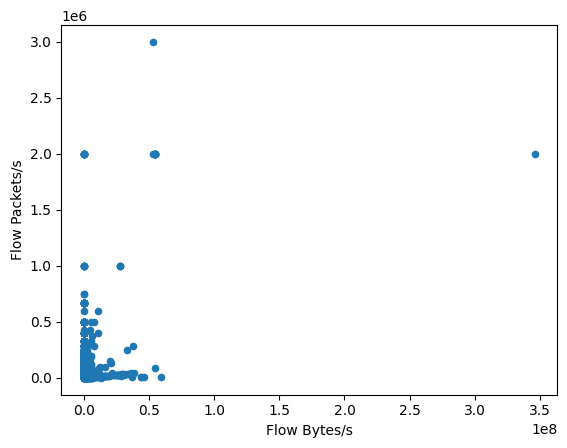

In [19]:
data_clean.plot(kind='scatter', x='Flow Bytes/s', y='Flow Packets/s')
pass

2. **`Flow Duration` vs `Total Fwd Packet`**  
    _Зачем:_ Позволяет увидеть, являются ли длинные по времени потоки также и насыщенными пакетами. Tor/VPN трафик часто имеет отличные от обычного трафика паттерны длительности.

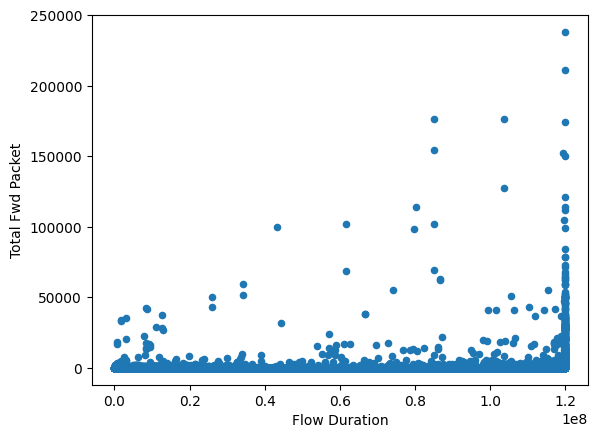

In [20]:
data_clean.plot(kind='scatter', x='Flow Duration', y='Total Fwd Packet')
pass

3. **`Average Packet Size` vs `Flow Duration`**  
    _Зачем:_ Выявляет паттерны передачи данных. Например, стриминг имеет стабильно большой размер пакета, а VoIP/Chat – маленький, но частый.

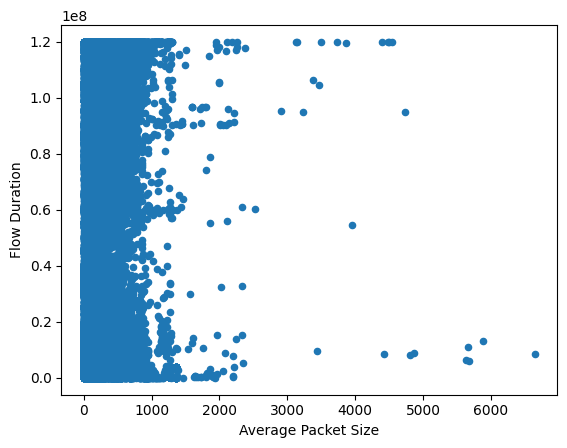

In [21]:
data_clean.plot(kind='scatter', x='Average Packet Size', y='Flow Duration')
pass

4. **`Fwd IAT Mean` vs `Bwd IAT Mean`** (Среднее время между прибытием пакетов вперед и назад)  
    _Зачем:_ Один из самых сильных признаков для отличия зашифрованного/туннелированного трафика (Tor/VPN) от открытого. У зашифрованных потоков распределение IAT часто более равномерное или имеет специфические кластеры.

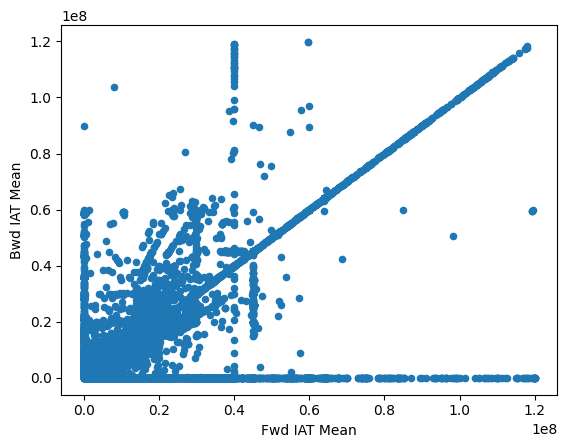

In [22]:
data_clean.plot(kind='scatter', x='Fwd IAT Mean', y='Bwd IAT Mean')
pass

5. **`Total Length of Fwd Packet` vs `Total Length of Bwd Packet`**  
    _Зачем:_ Показывает асимметрию трафика. Клиент-серверные загрузки имеют сильный перекос в одну сторону, тогда как P2P или VoIP могут быть более симметричными.

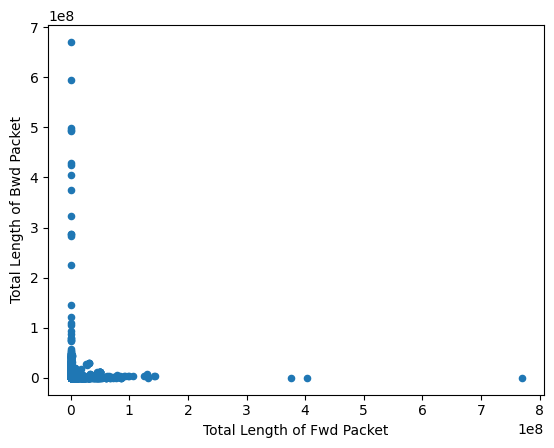

In [23]:
data_clean.plot(kind='scatter', x='Total Length of Fwd Packet', y='Total Length of Bwd Packet')
pass